In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs("charts", exist_ok=True)

In [2]:
df = pd.read_csv("train.csv")
print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({"Missing": missing, "Percent": missing_pct})[missing > 0]

,Missing,Percent
Age,177,19.9
Cabin,687,77.1
Embarked,2,0.2


In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
# Age: fill with the median age of each class and sex group
df["Age"] = df.groupby(["Pclass", "Sex"])["Age"].transform(lambda s: s.fillna(s.median()))

# Embarked: fill with the most common port
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Cabin: keep only whether a cabin was recorded, then drop the column
df["HasCabin"] = df["Cabin"].notna().astype(int)
df = df.drop(columns=["Cabin"])

print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


In [8]:
q1, q3 = df["Fare"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print("Fare outliers:", (df["Fare"] > upper).sum(), "| max fare:", df["Fare"].max())

Fare outliers: 116 | max fare: 512.3292


Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


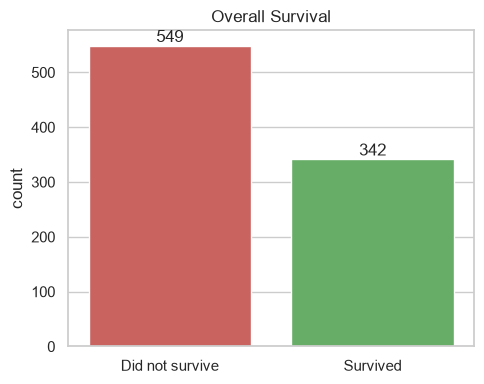

In [9]:
print(df["Survived"].value_counts(normalize=True).round(3))

plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df, x="Survived", hue="Survived", palette=["#d9534f", "#5cb85c"], legend=False)
ax.set_xticks([0, 1]); ax.set_xticklabels(["Did not survive", "Survived"])
for c in ax.containers:
    ax.bar_label(c)
plt.title("Overall Survival")
plt.xlabel("")
plt.tight_layout()
plt.savefig("charts/01_overall_survival.png", dpi=150)
plt.show()

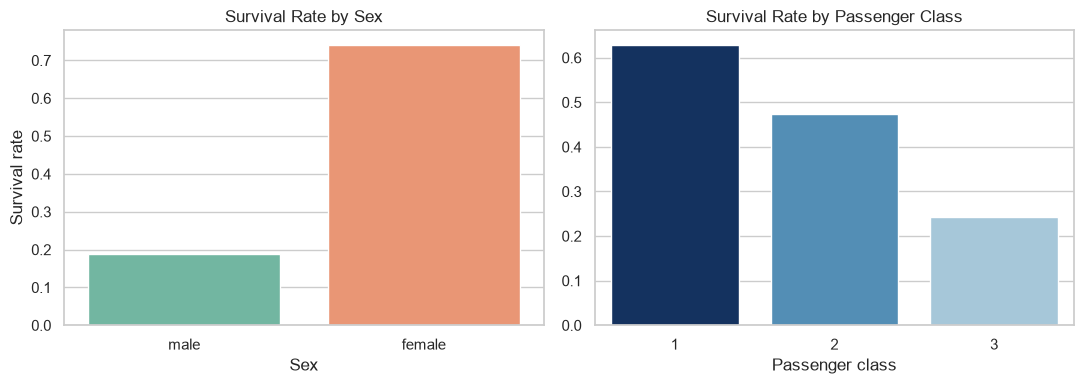

Sex
female    0.742
male      0.189
Name: Survived, dtype: float64
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.barplot(data=df, x="Sex", y="Survived", hue="Sex", palette="Set2",
            errorbar=None, dodge=False, legend=False, ax=axes[0])
axes[0].set_title("Survival Rate by Sex")
axes[0].set_ylabel("Survival rate")

sns.barplot(data=df, x="Pclass", y="Survived", hue="Pclass", palette=["#08306b", "#4292c6", "#9ecae1"],
            errorbar=None, dodge=False, legend=False, ax=axes[1])
axes[1].set_title("Survival Rate by Passenger Class")
axes[1].set_xlabel("Passenger class")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("charts/02_sex_class_survival.png", dpi=150)
plt.show()

print(df.groupby("Sex")["Survived"].mean().round(3))
print(df.groupby("Pclass")["Survived"].mean().round(3))

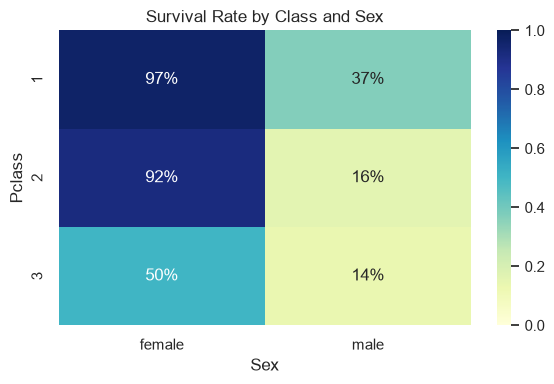

In [11]:
pivot = df.pivot_table(values="Survived", index="Pclass", columns="Sex", aggfunc="mean")

plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Survival Rate by Class and Sex")
plt.tight_layout()
plt.savefig("charts/03_class_sex_heatmap.png", dpi=150)
plt.show()

In [12]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

df["AgeGroup"] = pd.cut(
    df["Age"], bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"]
)

df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Miss", "Mrs", "Master"]), "Other")

print("AgeGroup" in df.columns)


True


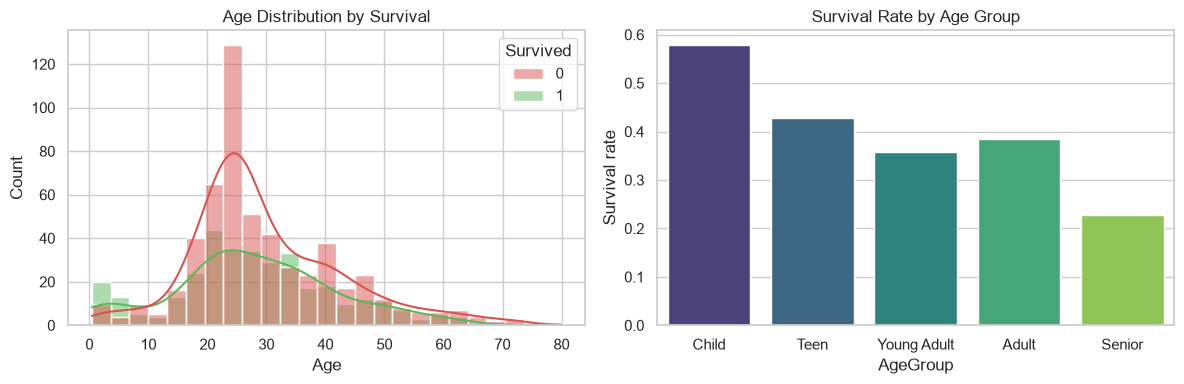

              mean  count
AgeGroup                 
Child        0.580     69
Teen         0.429     70
Young Adult  0.358    514
Adult        0.384    216
Senior       0.227     22


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data=df, x="Age", hue="Survived", bins=25, kde=True,
             palette=["#d9534f", "#5cb85c"], ax=axes[0])
axes[0].set_title("Age Distribution by Survival")

order = ["Child", "Teen", "Young Adult", "Adult", "Senior"]
sns.barplot(data=df, x="AgeGroup", y="Survived", order=order, hue="AgeGroup",
            palette="viridis", errorbar=None, dodge=False, legend=False, ax=axes[1])
axes[1].set_title("Survival Rate by Age Group")
axes[1].set_ylabel("Survival rate")

plt.tight_layout()
plt.savefig("charts/04_age.png", dpi=150)
plt.show()

print(df.groupby("AgeGroup", observed=True)["Survived"].agg(["mean", "count"]).round(3))

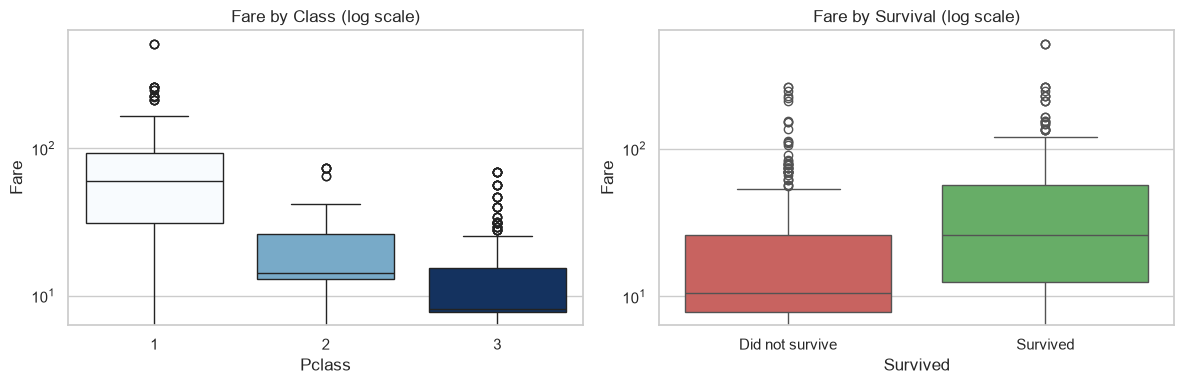

Survived
0    10.5
1    26.0
Name: Fare, dtype: float64


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.boxplot(data=df, x="Pclass", y="Fare", hue="Pclass", palette="Blues", legend=False, ax=axes[0])
axes[0].set_yscale("log")
axes[0].set_title("Fare by Class (log scale)")

sns.boxplot(data=df, x="Survived", y="Fare", hue="Survived",
            palette=["#d9534f", "#5cb85c"], legend=False, ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["Did not survive", "Survived"])
axes[1].set_title("Fare by Survival (log scale)")

plt.tight_layout()
plt.savefig("charts/05_fare.png", dpi=150)
plt.show()

print(df.groupby("Survived")["Fare"].median())

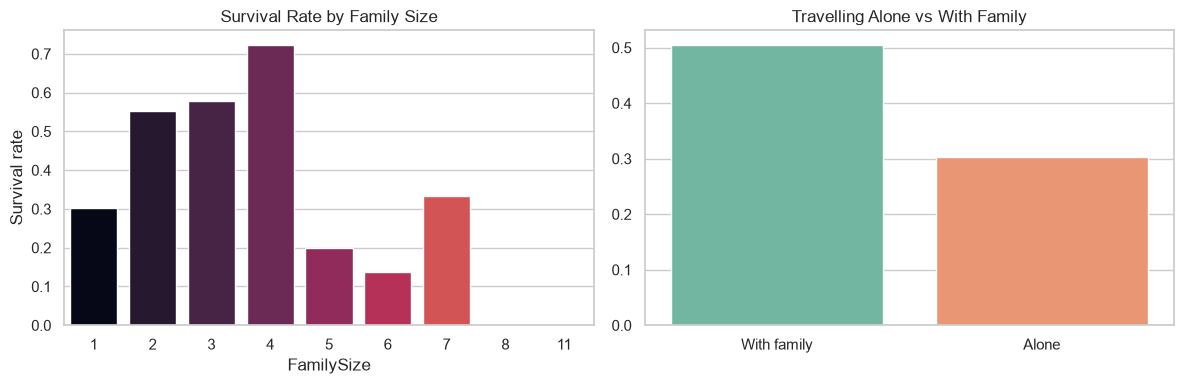

IsAlone
0    0.506
1    0.304
Name: Survived, dtype: float64


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=df, x="FamilySize", y="Survived", hue="FamilySize", palette="rocket",
            errorbar=None, dodge=False, legend=False, ax=axes[0])
axes[0].set_title("Survival Rate by Family Size")
axes[0].set_ylabel("Survival rate")

sns.barplot(data=df, x="IsAlone", y="Survived", hue="IsAlone", palette="Set2",
            errorbar=None, dodge=False, legend=False, ax=axes[1])
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["With family", "Alone"])
axes[1].set_title("Travelling Alone vs With Family")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("charts/06_family.png", dpi=150)
plt.show()

print(df.groupby("IsAlone")["Survived"].mean().round(3))

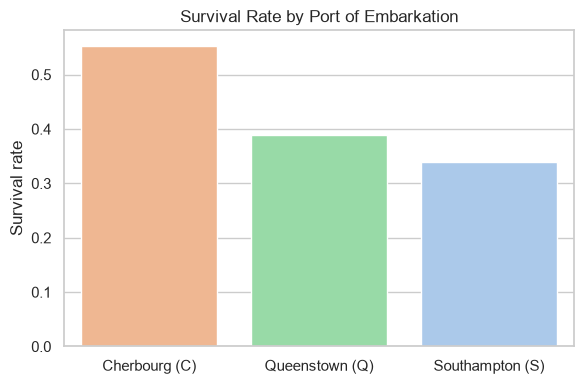

Embarked
C    0.554
Q    0.390
S    0.339
Name: Survived, dtype: float64
Pclass       1     2     3
Embarked                  
C         0.51  0.10  0.39
Q         0.03  0.04  0.94
S         0.20  0.25  0.55


In [16]:
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Embarked", y="Survived", order=["C", "Q", "S"],
            hue="Embarked", palette="pastel", errorbar=None, dodge=False, legend=False)
plt.xticks([0, 1, 2], ["Cherbourg (C)", "Queenstown (Q)", "Southampton (S)"])
plt.title("Survival Rate by Port of Embarkation")
plt.xlabel("")
plt.ylabel("Survival rate")
plt.tight_layout()
plt.savefig("charts/07_embarked.png", dpi=150)
plt.show()

print(df.groupby("Embarked")["Survived"].mean().round(3))
print(pd.crosstab(df["Embarked"], df["Pclass"], normalize="index").round(2))

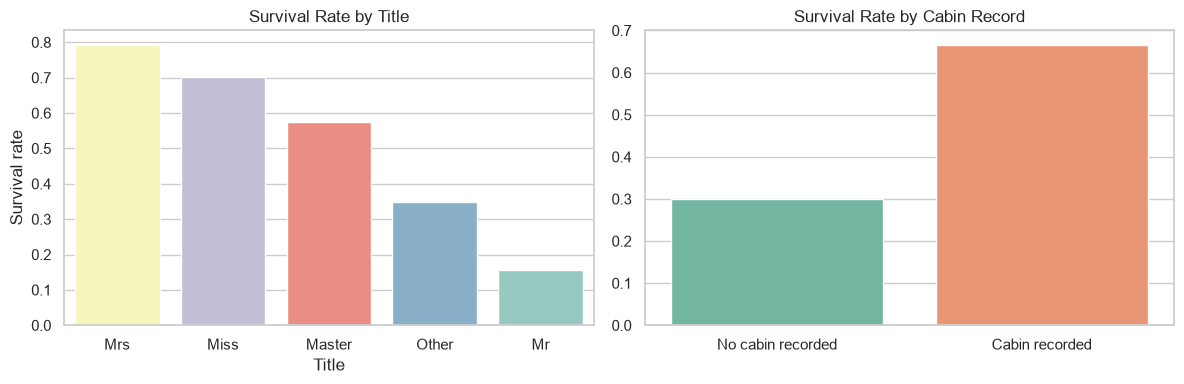

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

order = ["Mrs", "Miss", "Master", "Other", "Mr"]
sns.barplot(data=df, x="Title", y="Survived", order=order, hue="Title", palette="Set3",
            errorbar=None, dodge=False, legend=False, ax=axes[0])
axes[0].set_title("Survival Rate by Title")
axes[0].set_ylabel("Survival rate")

sns.barplot(data=df, x="HasCabin", y="Survived", hue="HasCabin", palette="Set2",
            errorbar=None, dodge=False, legend=False, ax=axes[1])
axes[1].set_xticks([0, 1]); axes[1].set_xticklabels(["No cabin recorded", "Cabin recorded"])
axes[1].set_title("Survival Rate by Cabin Record")
axes[1].set_xlabel("")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("charts/08_title_cabin.png", dpi=150)
plt.show()

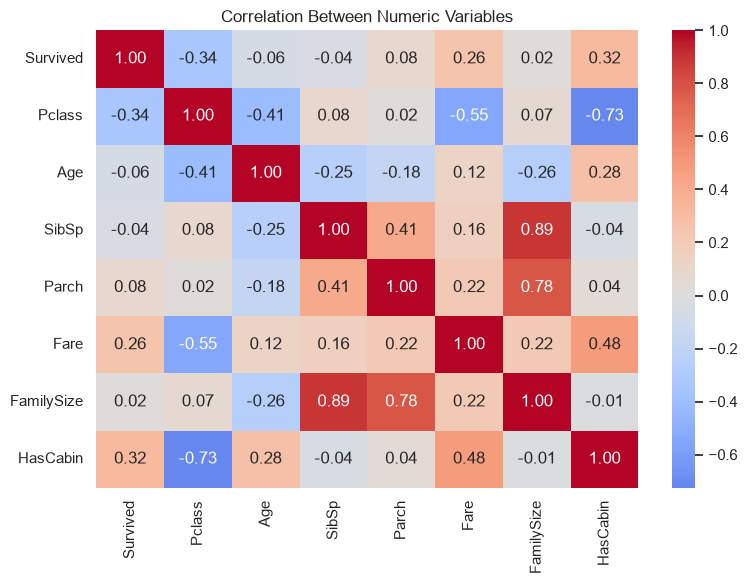

In [18]:
num_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "HasCabin"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Numeric Variables")
plt.tight_layout()
plt.savefig("charts/09_correlation.png", dpi=150)
plt.show()

## Key findings
1. Overall survival was 38.4%.
2. Sex was the strongest factor: 74.2% of women survived versus 18.9% of men.
3. Class mattered: survival fell from 63.0% (1st) to 47.3% (2nd) to 24.2% (3rd).
   1st-class women survived at 97%, 3rd-class men at 14%.
4. Children had the best chances (58%) and seniors the worst (23%).
5. Passengers with family (2 to 4 members) survived more than those travelling alone.
6. Higher fares and recorded cabins went with higher survival, both linked to class.
7. The Cherbourg advantage is explained by class, since more 1st-class passengers boarded there.

**Conclusion:** survival followed "women and children first", strongly shaped by
social class. Being a woman or child in a higher class gave the best chances, and
being a man in 3rd class gave the worst.